# Forecast soil-moisture time series at selected points

Observed (ESA CCI) and per-member model top-10 cm soil moisture through the forecasts at named points. `MODE = "cached"` caches the point series (one NetCDF per group under `data/fcst_lnd_model_evaluation/point_cache/`) and plots member spaghetti; `MODE = "direct"` reads without caching and plots ensemble mean ± spread.

## 1. Settings

In [1]:
from pathlib import Path

INPUT_DATA_ROOT = Path("/compyfs/zhan391/v3_dart_cda_scratch")
OBSERVATION_ROOT = Path("/compyfs/zhan391/acme_init/Observations")   # observations (shared archive)
LAND_SUPPORT_DIR = Path("/compyfs/zhan391/acme_init/lnd_sea_mask")   # land mask, soil-layer thickness
WORK_DIR = Path("/compyfs/zhan391/work_package/e3sm_dart_analysis")
DIAGNOSTIC_OUTPUT_ROOT = Path("/compyfs/www/zhan391/e3sm_dart/diag_dart_2026")
WORKFLOW_NAME = "fcst_lnd_model_evaluation"

FORECAST_GROUPS = {
    "Jan2012": {"models": ["CTRL10-S0", "CAPT10-S0", "DART20-S0", "DART40-S0"], "period": "201201-201203",
                "init_time": "2012-01-01"},
    "Jun2012": {"models": ["CTRL10-S1", "CAPT10-S1", "DART40-S1"], "period": "201206-201208",
                "init_time": "2012-06-01"},
}
OBS_KEY = "ESA_CCI"
VARIABLE_MAP = {"SOILWATER_10CM": "H2OSOI"}
DEPTH_CM = 10.0
MASK_LAND = False

POINTS = {
    "SOUTH_ASIA_MONSOON": {"name": "South Asia (E/C India–BoB)", "lat": 20.0, "lon": 85.0},
    "SOUTHERN_AFRICA": {"name": "Southern Africa", "lat": -22.0, "lon": 28.0},
}
POINTS_TAG = "SAS_SAF"            # cache key: change it when POINTS change
EXPERIMENTS_TO_PLOT = ["CAPT10-S0", "DART40-S0"]   # None -> every model of each group
MAX_MEMBERS = None                # e.g. 20, for readability
MODE = "cached"                   # "cached" (spaghetti, cached) or "direct" (mean +/- spread)
FIGURE_DPI = 200
# File collection: forecast ("fc") daily land time series, files <var>.EN##.<year>.nc
RUN, FREQ = "fc", "daily"
MODEL_TEMPLATE, ENS_PREFIX, ENS_WIDTH, ENS_START = "%(var)s.%(ens)s.%(year)d.nc", "EN", 2, 1

## 2. Project setup

In [2]:
import sys
repo = WORK_DIR.resolve()
if str(repo / "diagnostic") not in sys.path:
    sys.path.insert(0, str(repo / "diagnostic"))
from configs.output_paths import workflow_output_dirs
WORKFLOW_DATA_DIR, WORKFLOW_FIGURE_DIR = workflow_output_dirs(WORKFLOW_NAME, output_root=DIAGNOSTIC_OUTPUT_ROOT)

from configs.initial_land_experiment_registry import build_experiments
from configs.initial_land_observation_registry import get_obs_registry, get_obs_file
from util.initial_lnd_file_collection import FileCollectionConfig, S2SFileCollector
from util.initial_lnd_point_timeseries import SoilPointTSConfig, SoilPointTimeSeriesFromCollectedFiles

cache_dir = WORKFLOW_DATA_DIR / "point_cache"
figure_dir = WORKFLOW_FIGURE_DIR / "soil_point_timeseries"
for folder in (cache_dir, figure_dir):
    folder.mkdir(parents=True, exist_ok=True)
collector = S2SFileCollector(
    exp_list=FORECAST_GROUPS, exp_dict=build_experiments(INPUT_DATA_ROOT),
    obs_registry=get_obs_registry(OBSERVATION_ROOT),
    s2s_var_dict=VARIABLE_MAP, get_obs_file_func=get_obs_file,
)
model_var, obs_var = next(iter(VARIABLE_MAP.items()))
extractor = SoilPointTimeSeriesFromCollectedFiles(SoilPointTSConfig(
    model_var_name=model_var, obs_var_name=obs_var, depth_cm=DEPTH_CM,
    landmask_file=LAND_SUPPORT_DIR / "landmask_1x1.nc", mask_land=MASK_LAND,
))

/qfs/people/zhan391/.conda/envs/e3sm_analysis/lib/python3.12/site-packages/pyproj/network.py:59: UserWarning: pyproj unable to set PROJ database path.
  _set_context_ca_bundle_path(ca_bundle_path)


## 3. Extract and plot

sh: getfattr: command not found


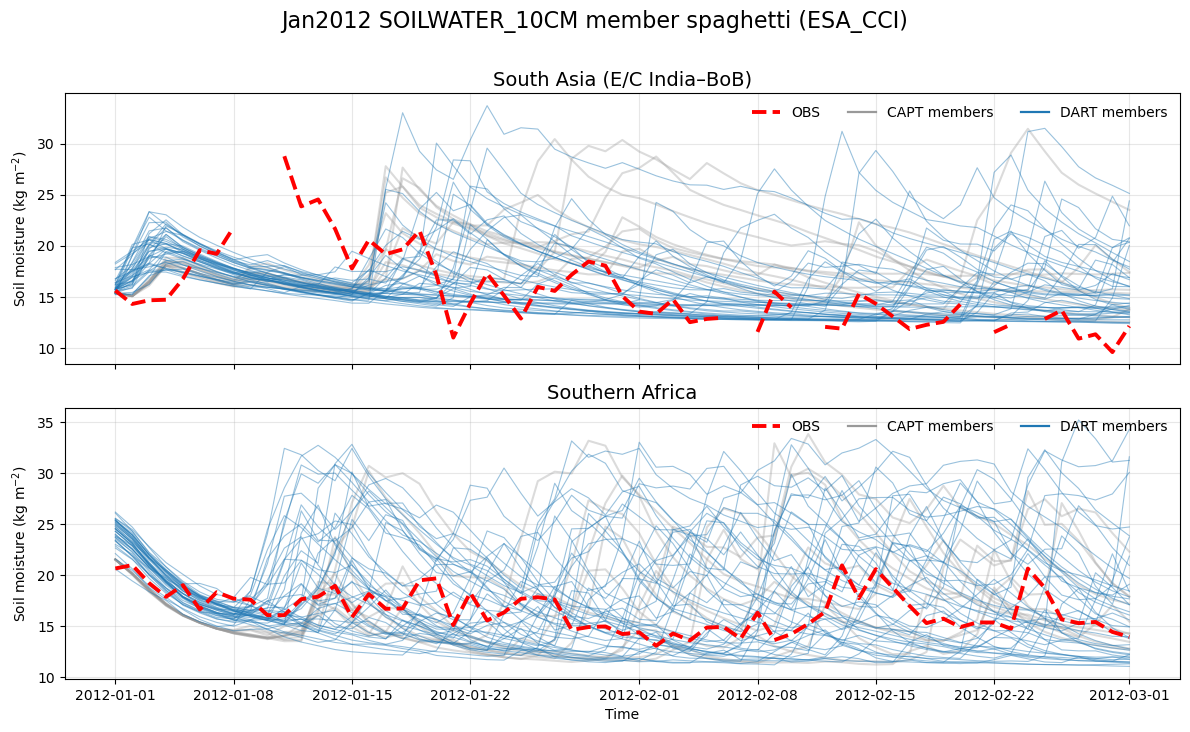

[FIGURE] /compyfs/www/zhan391/e3sm_dart/diag_dart_2026/figure/fcst_lnd_model_evaluation/soil_point_timeseries/soil_point_spaghetti_SAS_SAF_Jan2012_SOILWATER_10CM_201201-201203.pdf


In [3]:
for group, meta in FORECAST_GROUPS.items():
    exps = meta["models"] if EXPERIMENTS_TO_PLOT is None else EXPERIMENTS_TO_PLOT
    exps = [e for e in exps if e in meta["models"]]
    if not exps:
        continue
    cache_nc = cache_dir / f"soil_point_cache_{POINTS_TAG}_{group}_{model_var}_{meta['period']}_{OBS_KEY}.nc"
    needs_files = MODE == "direct" or not cache_nc.exists()
    if needs_files:
        files = collector.collect(
            FileCollectionConfig(group=group, freq=FREQ, run=RUN, obs=OBS_KEY, period=meta["period"],
                                 model_template=MODEL_TEMPLATE, ens_prefix=ENS_PREFIX,
                                 ens_width=ENS_WIDTH, ens_start=ENS_START),
            vars_to_process=[model_var], verbose=True,
        )[model_var]
    if MODE == "cached":
        if not cache_nc.exists():
            extractor.save_collected(files, points=POINTS, obs_key=OBS_KEY, exp_order=exps, out_nc=cache_nc)
            print(f"[{group}] Saved cached point data: {cache_nc}")
        output = figure_dir / f"soil_point_spaghetti_{POINTS_TAG}_{group}_{model_var}_{meta['period']}.pdf"
        extractor.plot_spaghetti(extractor.open_collected(cache_nc), exps=exps, out_png=output, show=True,
                                 title=f"{group} {model_var} member spaghetti ({OBS_KEY})",
                                 max_members=MAX_MEMBERS, dpi=FIGURE_DPI)
    else:
        output = figure_dir / f"soil_point_ts_{group}_{model_var}_{meta['period']}.pdf"
        extractor.plot(extractor.compute(files, points=POINTS, obs_key=OBS_KEY, exp_order=exps), exps=exps,
                       out_png=output, show=True, title=f"{group} {model_var} point time series ({OBS_KEY})",
                       dpi=FIGURE_DPI)
    print(f"[FIGURE] {output}")